# Actividad 5: Clasificación de pólizas de seguros de vida

## Proyecto de Machine Learning con MLflow

**Objetivo:** desarrollar y comparar modelos de Regresión Logística y Random Forest para clasificar pólizas según su estado de vigencia o cancelación.

**Variable objetivo:** TARGET, donde 1 representa Lapse y 0 representa Inforce.

## 1. Obtención del dataset

In [5]:

import kagglehub

path = kagglehub.dataset_download(
    "blackclover1/life-insurance-policy-data"
)

print("Dataset descargado en:", path)


100%|██████████| 1.41M/1.41M [00:00<00:00, 108MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/blackclover1/life-insurance-policy-data/versions/1


In [ ]:

from pathlib import Path
import shutil

# Identificar el repositorio desde el directorio de trabajo
# Ejecutar el notebook desde la raíz o desde fuentes/

directorio_actual = Path.cwd().resolve()

candidatos = [
    directorio_actual,
    directorio_actual.parent
]

repositorios = [
    ruta for ruta in candidatos
    if (ruta / "fuentes/datos_prep.py").is_file()
    and (ruta / "fuentes/train.py").is_file()
]

if len(repositorios) != 1:
    raise RuntimeError(
        "No se pudo identificar el repositorio. "
        "Ejecuta el notebook desde la raíz del proyecto "
        "o desde la carpeta fuentes."
    )

BASE = repositorios[0]

print("Directorio del proyecto:", BASE)

# Directorios de datos
DATOS_INI = BASE / "datos/datos_ini"
DATOS_LIMP = BASE / "datos/datos_limp"

DATOS_INI.mkdir(parents=True, exist_ok=True)
DATOS_LIMP.mkdir(parents=True, exist_ok=True)

# Localizar archivo descargado
archivos_csv = list(Path(path).rglob("Kaggle.csv"))

if len(archivos_csv) != 1:
    raise FileNotFoundError(
        "No se encontró un único archivo Kaggle.csv."
    )

origen_csv = archivos_csv[0]
destino_csv = DATOS_INI / "Kaggle.csv"

# Copiar dataset original
if origen_csv.resolve() != destino_csv.resolve():
    shutil.copy2(origen_csv, destino_csv)

print("Dataset disponible:", destino_csv)


## 2. Análisis exploratorio y calidad de datos

Se examinan los tipos de datos, valores faltantes, registros duplicados, distribuciones, anomalías y consistencia de las variables.

#Limipeza de datos

In [8]:

import pandas as pd

ruta = BASE / "datos/datos_ini/Kaggle.csv"

df = pd.read_csv(ruta, sep=";")

print("Dimensiones:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeros registros:")
display(df.head())


Dimensiones: (185560, 22)

Columnas:
['CHANNEL1', 'CHANNEL2', 'CHANNEL3', 'ENTRY AGE', 'SEX', 'POLICY TYPE 1', 'POLICY TYPE 2', 'POLICY TYPE 3', 'PAYMENT MODE', 'POLICY STATUS', 'BENEFIT', 'NON LAPSE GUARANTEED', 'SUBSTANDARD RISK', 'NUMBER OF ADVANCE PREMIUM', 'INITIAL BENEFIT', 'Full Benefit?', 'Policy Year (Decimal)', 'Policy Year', 'Premium', 'Issue Date', 'Unnamed: 20', 'Unnamed: 21']

Primeros registros:


,CHANNEL1,CHANNEL2,CHANNEL3,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,...,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,Unnamed: 20,Unnamed: 21
0,1,1,1,36,F,1,1,A,Annually,Inforce,...,0.0,0,0.0,N,8.000000,9,280,Aug-11,NaN,NaN
1,1,1,1,42,M,1,2,A,Annually,Inforce,...,0.0,0,0.0,N,8.000000,9,200,Aug-11,NaN,NaN
2,1,1,2,40,M,2,3,A,Annually,Lapse,...,0.0,0,0.0,N,8.000000,9,"1,289",Aug-11,NaN,NaN
3,1,1,3,39,M,1,2,A,Monthly,Lapse,...,0.0,0,0.0,N,8.000000,9,216,Aug-11,NaN,NaN
4,1,1,4,44,M,1,2,A,Annually,Lapse,...,0.0,0,0.0,N,7.916667,8,140,Sep-11,NaN,NaN


In [11]:
#Identificar tipos de datos
print("==========================TIPOS DE DATOS")
print(df.dtypes)

#Identificacion de nulos
print("\n==========================VALORES NULOS POR COLUMNA")
print(df.isnull().sum().sort_values(ascending=False))

#Identificacion de estatus
print("\n==========================DISTRIBUCIÓN DE ESTATUS")
print(df["POLICY STATUS"].value_counts(dropna=False))

#Identificar registros duplicados
print("\n==========================REGISTROS DUPLICADOS")
print(df.duplicated().sum())

==========================TIPOS DE DATOS
CHANNEL1                       int64
CHANNEL2                       int64
CHANNEL3                       int64
ENTRY AGE                      int64
SEX                           object
POLICY TYPE 1                  int64
POLICY TYPE 2                  int64
POLICY TYPE 3                 object
PAYMENT MODE                  object
POLICY STATUS                 object
BENEFIT                       object
NON LAPSE GUARANTEED          object
SUBSTANDARD RISK             float64
NUMBER OF ADVANCE PREMIUM      int64
INITIAL BENEFIT              float64
Full Benefit?                 object
Policy Year (Decimal)        float64
Policy Year                    int64
Premium                       object
Issue Date                    object
Unnamed: 20                  float64
Unnamed: 21                  float64
dtype: object

==========================VALORES NULOS POR COLUMNA
Unnamed: 20                  185560
Unnamed: 21                  185560
CHANNE

In [12]:
# Analizar duplicados por estado de póliza

duplicados = df[df.duplicated(keep=False)]

print("Total de filas pertenecientes a grupos duplicados:")
print(len(duplicados))

print("\nDuplicados por estado de póliza:")
print(duplicados["POLICY STATUS"].value_counts())

print("\nEjemplos de registros duplicados:")
display(duplicados.head(10))

Total de filas pertenecientes a grupos duplicados:
21443

Duplicados por estado de póliza:
POLICY STATUS
Lapse        13759
Inforce       6506
Surrender     1172
Death            4
Expired          2
Name: count, dtype: int64

Ejemplos de registros duplicados:


,CHANNEL1,CHANNEL2,CHANNEL3,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,...,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,Unnamed: 20,Unnamed: 21
67,1,1,10,27,M,2,3,A,Semiannually,Lapse,...,0.0,0,0.0,N,5.833333,6,58,Oct-13,NaN,NaN
108,1,1,15,25,F,1,2,A,Monthly,Lapse,...,0.0,0,0.0,N,7.416667,8,151,Mar-12,NaN,NaN
136,1,1,1,48,M,1,2,A,Quaterly,Lapse,...,0.0,0,0.0,N,5.416667,6,276,Mar-14,NaN,NaN
146,1,1,1,28,F,1,2,A,Monthly,Lapse,...,0.0,0,0.0,N,8.000000,9,216,Aug-11,NaN,NaN
163,1,1,2,32,M,2,3,A,Monthly,Lapse,...,0.0,0,0.0,N,7.666667,8,68,Dec-11,NaN,NaN
198,1,1,1,36,M,2,3,A,Monthly,Lapse,...,0.0,0,0.0,N,6.833333,7,250,Oct-12,NaN,NaN
204,1,1,10,21,F,2,3,A,Semiannually,Lapse,...,0.0,0,0.0,N,5.833333,6,58,Oct-13,NaN,NaN
205,1,1,10,21,F,2,3,A,Semiannually,Lapse,...,0.0,0,0.0,N,5.833333,6,58,Oct-13,NaN,NaN
229,1,1,1,46,M,1,2,A,Monthly,Lapse,...,0.0,0,0.0,N,7.916667,8,151,Sep-11,NaN,NaN
233,1,1,1,27,M,2,3,A,Monthly,Lapse,...,0.0,0,0.0,N,7.833333,8,261,Oct-11,NaN,NaN


In [13]:
# Analizar frecuencia de registros idénticos

frecuencia = (
    df.value_counts(dropna=False)
    .reset_index(name="Frecuencia")
    .sort_values("Frecuencia", ascending=False)
)

print("Número de combinaciones únicas:")
print(len(frecuencia))

print("\nDistribución de frecuencias:")
print(
    frecuencia["Frecuencia"]
    .value_counts()
    .sort_index()
)

print("\nMáxima cantidad de repeticiones:")
print(frecuencia["Frecuencia"].max())

Número de combinaciones únicas:
173676

Distribución de frecuencias:
Frecuencia
1     164117
2       7994
3       1154
4        268
5         80
6         23
7         10
8         12
9          4
10         3
11         1
13         7
14         1
17         1
18         1
Name: count, dtype: int64

Máxima cantidad de repeticiones:
18


In [14]:
# Diagnóstico de los campos monetarios

for columna in ["BENEFIT", "Premium"]:
    print("\n" + "=" * 45)
    print("COLUMNA:", columna)

    print("\nPrimeros valores:")
    print(df[columna].head(10).tolist())

    print("\nValores más frecuentes:")
    print(df[columna].value_counts().head(10))

    valores = pd.to_numeric(
        df[columna].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

    print("\nValores que no se pueden convertir:")
    print(valores.isna().sum())

    print("\nValores negativos:")
    print((valores < 0).sum())

    print("\nValores iguales a cero:")
    print((valores == 0).sum())


COLUMNA: BENEFIT

Primeros valores:
[' 200,000 ', ' 100,000 ', ' 80,000 ', ' 100,000 ', ' 100,000 ', ' 40,000 ', ' 20,000 ', ' 100,000 ', ' 20,000 ', ' 20,000 ']

Valores más frecuentes:
BENEFIT
20,000     33486
-          23664
10,000     15719
60          8164
50,000      7720
40          7241
4,000       6080
100         5850
40,000      5573
30,000      5192
Name: count, dtype: int64

Valores que no se pueden convertir:
23664

Valores negativos:
0

Valores iguales a cero:
0

COLUMNA: Premium

Primeros valores:
[' 280 ', ' 200 ', ' 1,289 ', ' 216 ', ' 140 ', ' 336 ', ' 537 ', ' 200 ', ' 82 ', ' 73 ']

Valores más frecuentes:
Premium
-         77127
480       10242
240        9158
1,200      4517
720        3885
600        2664
960        2250
120        2192
408        2040
6          2028
Name: count, dtype: int64

Valores que no se pueden convertir:
77127

Valores negativos:
2

Valores iguales a cero:
20


In [17]:
# Analizar valores faltantes por estado de póliza

for columna in ["BENEFIT", "Premium"]:

    valores = pd.to_numeric(
        df[columna].astype(str)
        .str.strip()
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    resumen = pd.DataFrame({
        "Estado": df["POLICY STATUS"],
        "Faltante": valores.isna()
    })

    tabla = resumen.groupby("Estado")["Faltante"].agg(
        Total="count",
        Faltantes="sum",
        Porcentaje="mean"
    )

    tabla["Porcentaje"] = (
        tabla["Porcentaje"] * 100
    ).round(2)

    print("\n" + "=" * 45)
    print("ANÁLISIS DE:", columna)
    display(tabla)


ANÁLISIS DE: BENEFIT


,Total,Faltantes,Porcentaje
Estado,,,
Death,513,80,15.59
Expired,135,0,0.00
Inforce,65814,9344,14.20
Lapse,98865,10409,10.53
Surrender,20233,3831,18.93



ANÁLISIS DE: Premium


,Total,Faltantes,Porcentaje
Estado,,,
Death,513,210,40.94
Expired,135,42,31.11
Inforce,65814,26087,39.64
Lapse,98865,42045,42.53
Surrender,20233,8743,43.21


In [18]:
# Diagnóstico de valores extremos

for columna in ["BENEFIT", "Premium"]:

    valores = pd.to_numeric(
        df[columna].astype(str)
        .str.strip()
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    print("\n" + "=" * 45)
    print("VARIABLE:", columna)

    print("\nEstadísticas descriptivas:")
    print(
        valores.describe(
            percentiles=[0.01, 0.05, 0.25, 0.50,
                         0.75, 0.95, 0.99]
        )
    )

    print("\nValores negativos:")
    print((valores < 0).sum())

    print("\nValores iguales a cero:")
    print((valores == 0).sum())


VARIABLE: BENEFIT

Estadísticas descriptivas:
count    1.618960e+05
mean     2.344718e+04
std      6.182418e+04
min      2.000000e+01
1%       3.400000e+01
5%       4.000000e+01
25%      8.000000e+02
50%      1.200000e+04
75%      2.000000e+04
95%      8.000000e+04
99%      2.000000e+05
max      5.000000e+06
Name: BENEFIT, dtype: float64

Valores negativos:
0

Valores iguales a cero:
0

VARIABLE: Premium

Estadísticas descriptivas:
count    108433.000000
mean       1273.247877
std        5836.882869
min        -111.000000
1%            2.000000
5%            9.000000
25%         120.000000
50%         432.000000
75%         960.000000
95%        4320.000000
99%       14924.640000
max      444000.000000
Name: Premium, dtype: float64

Valores negativos:
2

Valores iguales a cero:
20


In [19]:
# Investigar primas negativas y primas iguales a cero

premium_num = pd.to_numeric(
    df["Premium"].astype(str)
    .str.strip()
    .str.replace(",", "", regex=False),
    errors="coerce"
)

casos_especiales = df.loc[
    premium_num <= 0,
    [
        "POLICY STATUS",
        "PAYMENT MODE",
        "BENEFIT",
        "Premium",
        "POLICY TYPE 1",
        "POLICY TYPE 2",
        "POLICY TYPE 3",
        "Policy Year"
    ]
].copy()

print("Total de casos con prima menor o igual a cero:")
print(len(casos_especiales))

print("\nDistribución por estado de póliza:")
print(casos_especiales["POLICY STATUS"].value_counts())

print("\nDistribución por modalidad de pago:")
print(casos_especiales["PAYMENT MODE"].value_counts())

print("\nDetalle de los casos:")
display(casos_especiales)

Total de casos con prima menor o igual a cero:
22

Distribución por estado de póliza:
POLICY STATUS
Inforce    15
Expired     6
Lapse       1
Name: count, dtype: int64

Distribución por modalidad de pago:
PAYMENT MODE
Single Premium    19
Annually           2
Monthly            1
Name: count, dtype: int64

Detalle de los casos:


,POLICY STATUS,PAYMENT MODE,BENEFIT,Premium,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,Policy Year
39943,Lapse,Monthly,60,0,3,9,C,6
111895,Inforce,Annually,200,-111,3,12,C,5
112474,Inforce,Annually,200,-103,3,12,C,5
180964,Inforce,Single Premium,"2,000",0,13,60,B,1
180974,Inforce,Single Premium,"2,000",0,13,60,B,1
181087,Expired,Single Premium,"2,000",0,13,60,B,2
181106,Inforce,Single Premium,"2,000",0,13,60,B,1
181242,Inforce,Single Premium,"2,000",0,13,60,B,1
181328,Expired,Single Premium,"6,000",0,13,59,A,2
181655,Inforce,Single Premium,"2,000",0,13,60,B,1


In [20]:
# Diagnóstico de variables categóricas

columnas_categoricas = df.select_dtypes(
    include=["object"]
).columns

for columna in columnas_categoricas:

    print("\n" + "=" * 50)
    print("VARIABLE:", columna)

    print("\nNúmero de categorías distintas:")
    print(df[columna].nunique(dropna=False))

    print("\nFrecuencia de categorías:")
    print(df[columna].value_counts(dropna=False).head(20))


VARIABLE: SEX

Número de categorías distintas:
2

Frecuencia de categorías:
SEX
M    107465
F     78095
Name: count, dtype: int64

VARIABLE: POLICY TYPE 3

Número de categorías distintas:
5

Frecuencia de categorías:
POLICY TYPE 3
A    74657
C    73048
D    18300
E    16171
B     3384
Name: count, dtype: int64

VARIABLE: PAYMENT MODE

Número de categorías distintas:
5

Frecuencia de categorías:
PAYMENT MODE
Monthly           141604
Annually           25954
Quaterly           10135
Semiannually        5262
Single Premium      2605
Name: count, dtype: int64

VARIABLE: POLICY STATUS

Número de categorías distintas:
5

Frecuencia de categorías:
POLICY STATUS
Lapse        98865
Inforce      65814
Surrender    20233
Death          513
Expired        135
Name: count, dtype: int64

VARIABLE: BENEFIT

Número de categorías distintas:
2800

Frecuencia de categorías:
BENEFIT
20,000      33486
-           23664
10,000      15719
60           8164
50,000       7720
40           7241
4,000        60

In [21]:
# Diagnóstico de variables temporales

fechas = pd.to_datetime(
    df["Issue Date"].astype(str).str.strip(),
    format="%b-%y",
    errors="coerce"
)

print("Fechas que no se pudieron convertir:")
print(fechas.isna().sum())

print("\nFecha mínima:")
print(fechas.min())

print("\nFecha máxima:")
print(fechas.max())

print("\nDistribución por año de contratación:")
print(fechas.dt.year.value_counts().sort_index())

print("\nEstadísticas de antigüedad de pólizas:")
print(
    df[
        ["Policy Year", "Policy Year (Decimal)"]
    ].describe()
)

print("\nRegistros con antigüedad menor o igual a cero:")
print((df["Policy Year"] <= 0).sum())

Fechas que no se pudieron convertir:
0

Fecha mínima:
2011-08-01 00:00:00

Fecha máxima:
2019-08-01 00:00:00

Distribución por año de contratación:
Issue Date
2011      454
2012     2082
2013    23721
2014    21089
2015    32301
2016    38355
2017    27548
2018    25336
2019    14674
Name: count, dtype: int64

Estadísticas de antigüedad de pólizas:
         Policy Year  Policy Year (Decimal)
count  185560.000000          185560.000000
mean        3.826822               3.284277
std         1.849674               1.832295
min         1.000000               0.000000
25%         2.000000               1.833333
50%         4.000000               3.250000
75%         5.000000               4.666667
max         9.000000               8.000000

Registros con antigüedad menor o igual a cero:
0


In [22]:
# Revisar consistencia entre las variables de antigüedad

temporal = df[
    ["Policy Year", "Policy Year (Decimal)"]
].copy()

temporal["Diferencia"] = (
    temporal["Policy Year"]
    - temporal["Policy Year (Decimal)"]
)

print("Estadísticas de la diferencia:")
print(temporal["Diferencia"].describe())

print("\nRegistros con diferencia negativa:")
print((temporal["Diferencia"] < 0).sum())

print("\nRegistros con diferencia mayor a 1:")
print((temporal["Diferencia"] > 1).sum())

print("\nCorrelación entre ambas variables:")
print(
    temporal[
        ["Policy Year", "Policy Year (Decimal)"]
    ].corr()
)

print("\nEjemplos de las combinaciones:")
display(
    temporal.drop_duplicates()
    .sort_values("Policy Year")
    .head(20)
)

Estadísticas de la diferencia:
count    185560.000000
mean          0.542544
std           0.288152
min           0.083333
25%           0.333333
50%           0.583333
75%           0.750000
max           1.000000
Name: Diferencia, dtype: float64

Registros con diferencia negativa:
0

Registros con diferencia mayor a 1:
0

Correlación entre ambas variables:
                       Policy Year  Policy Year (Decimal)
Policy Year               1.000000               0.987795
Policy Year (Decimal)     0.987795               1.000000

Ejemplos de las combinaciones:


,Policy Year,Policy Year (Decimal),Diferencia
1386,1,0.416667,0.583333
934,1,0.666667,0.333333
1146,1,0.083333,0.916667
6441,1,0.583333,0.416667
6393,1,0.500000,0.500000
6251,1,0.833333,0.166667
6250,1,0.750000,0.250000
6676,1,0.000000,1.000000
6633,1,0.166667,0.833333
6600,1,0.250000,0.750000


## 3. Preparación y limpieza de datos

Se aplican las reglas de limpieza, conversión de variables monetarias, estandarización de categorías y tratamiento de fechas.

In [23]:

# Verificar estructura del proyecto

carpetas = [
    BASE / "datos/datos_ini",
    BASE / "datos/datos_limp",
    BASE / "fuentes",
    BASE / "resultados"
]

for carpeta in carpetas:
    carpeta.mkdir(parents=True, exist_ok=True)
    print("Carpeta disponible:", carpeta)

assert (BASE / "datos/datos_ini/Kaggle.csv").is_file()

print("\nEstructura verificada.")


Dataset original copiado correctamente.
📁 Actividad5JCP
    📄 Kaggle.csv
    📁 fuentes
    📁 datos
        📁 datos_ini
            📄 Kaggle.csv
        📁 datos_limp


In [ ]:

import sys

FUENTES = BASE / "fuentes"

if str(FUENTES) not in sys.path:
    sys.path.insert(0, str(FUENTES))

from datos_prep import preparar_datos

ruta_datos = BASE / "datos/datos_ini/Kaggle.csv"

df_preparado = preparar_datos(ruta_datos)

print("\nDimensiones:", df_preparado.shape)
print(df_preparado["TARGET"].value_counts())

assert df_preparado.shape == (164679, 22)


In [36]:

# Verificación del dataset preparado

print("Dimensiones:")
print(df_preparado.shape)

print("\nDistribución de TARGET:")
print(df_preparado["TARGET"].value_counts())

print("\nPrimeros registros:")
display(df_preparado.head())


Registros originales: 185560

Dimensiones:
(164679, 21)

Distribución de TARGET:
TARGET
1    98865
0    65814
Name: count, dtype: int64

Primeros registros:


,CHANNEL1,CHANNEL2,CHANNEL3,ENTRY AGE,SEX,POLICY TYPE 1,POLICY TYPE 2,POLICY TYPE 3,PAYMENT MODE,POLICY STATUS,...,NON LAPSE GUARANTEED,SUBSTANDARD RISK,NUMBER OF ADVANCE PREMIUM,INITIAL BENEFIT,Full Benefit?,Policy Year (Decimal),Policy Year,Premium,Issue Date,TARGET
0,1,1,1,36,F,1,1,A,Annually,Inforce,...,NO NLG,0.0,0,0.0,N,8.000000,9,280,Aug-11,0
1,1,1,1,42,M,1,2,A,Annually,Inforce,...,NO NLG,0.0,0,0.0,N,8.000000,9,200,Aug-11,0
2,1,1,2,40,M,2,3,A,Annually,Lapse,...,NO NLG,0.0,0,0.0,N,8.000000,9,"1,289",Aug-11,1
3,1,1,3,39,M,1,2,A,Monthly,Lapse,...,NO NLG,0.0,0,0.0,N,8.000000,9,216,Aug-11,1
4,1,1,4,44,M,1,2,A,Annually,Lapse,...,NO NLG,0.0,0,0.0,N,7.916667,8,140,Sep-11,1


In [38]:




print("\nTipos de datos:")
print(df_preparado[["BENEFIT", "Premium"]].dtypes)

print("\nValores faltantes:")
print(df_preparado[["BENEFIT", "Premium"]].isna().sum())

print("\nPrimas negativas:")
print((df_preparado["Premium"] < 0).sum())

print("\nPrimas iguales a cero:")
print((df_preparado["Premium"] == 0).sum())

print("\nDimensiones:")
print(df_preparado.shape)

Registros originales: 185560

Tipos de datos:
BENEFIT    float64
Premium    float64
dtype: object

Valores faltantes:
BENEFIT    19753
Premium    68134
dtype: int64

Primas negativas:
0

Primas iguales a cero:
14

Dimensiones:
(164679, 21)


In [40]:




print("\nDistribución de PAYMENT MODE:")
print(df_preparado["PAYMENT MODE"].value_counts())

print("\nValores con escritura anterior:")
print((df_preparado["PAYMENT MODE"] == "Quaterly").sum())

print("\nDimensiones:")
print(df_preparado.shape)

Registros originales: 185560

Distribución de PAYMENT MODE:
PAYMENT MODE
Monthly           125191
Annually           23504
Quarterly           8962
Semiannually        4586
Single Premium      2436
Name: count, dtype: int64

Valores con escritura anterior:
0

Dimensiones:
(164679, 21)


In [42]:




print("\nTipos de datos temporales:")
print(
    df_preparado[
        ["Issue Date", "Issue Year", "Issue Month"]
    ].dtypes
)

print("\nFechas no convertidas:")
print(df_preparado["Issue Date"].isna().sum())

print("\nRango de fechas:")
print(df_preparado["Issue Date"].min())
print(df_preparado["Issue Date"].max())

print("\nPrimeros registros:")
display(
    df_preparado[
        ["Issue Date", "Issue Year", "Issue Month"]
    ].head()
)

print("\nDimensiones:")
print(df_preparado.shape)

Registros originales: 185560

Tipos de datos temporales:
Issue Date     datetime64[ns]
Issue Year              int32
Issue Month             int32
dtype: object

Fechas no convertidas:
0

Rango de fechas:
2011-08-01 00:00:00
2019-08-01 00:00:00

Primeros registros:


,Issue Date,Issue Year,Issue Month
0,2011-08-01,2011,8
1,2011-08-01,2011,8
2,2011-08-01,2011,8
3,2011-08-01,2011,8
4,2011-09-01,2011,9



Dimensiones:
(164679, 23)


In [44]:




print("\nDimensiones:")
print(df_preparado.shape)

print("\n¿Existe Policy Year?")
print("Policy Year" in df_preparado.columns)

print("\n¿Existe Policy Year (Decimal)?")
print("Policy Year (Decimal)" in df_preparado.columns)

print("\nDistribución de TARGET:")
print(df_preparado["TARGET"].value_counts())

Registros originales: 185560

Dimensiones:
(164679, 22)

¿Existe Policy Year?
False

¿Existe Policy Year (Decimal)?
True

Distribución de TARGET:
TARGET
1    98865
0    65814
Name: count, dtype: int64


In [ ]:
ruta_destino = BASE / "datos/datos_limp/datos_preparados_v1.csv"
ruta_destino.parent.mkdir(parents=True, exist_ok=True)

from pathlib import Path
import pandas as pd

# Validaciones finales del dataset preparado


ruta_destino = BASE / "datos/datos_limp/datos_preparados_v1.csv"

# Ejecutar preparación

# Validaciones
assert df_preparado.shape == (164679, 22)
assert df_preparado["TARGET"].notna().all()
assert set(df_preparado["TARGET"].unique()) == {0, 1}
assert df_preparado["Issue Date"].notna().all()
assert (df_preparado["Premium"].dropna() >= 0).all()
assert "Policy Year" not in df_preparado.columns

print("\nTodas las validaciones fueron satisfactorias.")

# Guardar primera versión preparada
df_preparado.to_csv(
    ruta_destino,
    index=False,
    sep=";",
    date_format="%Y-%m-%d"
)

print("\nArchivo guardado correctamente:")
print(ruta_destino)

print("\nTamaño del archivo:")
print(round(ruta_destino.stat().st_size / (1024**2), 2), "MB")

print("\nDimensiones:")
print(df_preparado.shape)

## 4. Validaciones adicionales de calidad

Se revisan perfiles repetidos y posibles relaciones entre variables para reducir riesgos de fuga de información.

In [46]:
# Diagnóstico de duplicados en datos preparados v1

print("=" * 50)
print("DIAGNÓSTICO DE DUPLICADOS")

# 1. Duplicados exactos
duplicados_exactos = df_preparado.duplicated().sum()

print("\nDuplicados exactos:")
print(duplicados_exactos)

# 2. Comparar características sin la variable objetivo
columnas_predictoras = [
    col for col in df_preparado.columns
    if col not in ["TARGET", "POLICY STATUS"]
]

# 3. Registros con características repetidas
duplicados_caracteristicas = df_preparado.duplicated(
    subset=columnas_predictoras,
    keep=False
)

print("\nFilas con características repetidas:")
print(duplicados_caracteristicas.sum())

# 4. Identificar perfiles con diferentes estados
perfiles = (
    df_preparado
    .groupby(columnas_predictoras, dropna=False)["TARGET"]
    .nunique()
)

perfiles_contradictorios = (perfiles > 1).sum()

print("\nPerfiles con características idénticas")
print("pero diferentes estados de póliza:")
print(perfiles_contradictorios)

# 5. Distribución de duplicados exactos
print("\nDuplicados exactos por estado:")
print(
    df_preparado.loc[
        df_preparado.duplicated(keep=False),
        "POLICY STATUS"
    ].value_counts()
)

DIAGNÓSTICO DE DUPLICADOS

Duplicados exactos:
11229

Filas con características repetidas:
26594

Perfiles con características idénticas
pero diferentes estados de póliza:
3811

Duplicados exactos por estado:
POLICY STATUS
Lapse      13759
Inforce     6506
Name: count, dtype: int64


In [47]:
import pandas as pd

# Seleccionar características predictoras
columnas_predictoras = [
    col for col in df_preparado.columns
    if col not in ["TARGET", "POLICY STATUS"]
]

# Crear identificador de grupo
df_grupos = df_preparado.copy()

df_grupos["GRUPO_PERFIL"] = (
    df_grupos.groupby(
        columnas_predictoras,
        dropna=False,
        sort=False
    ).ngroup()
)

print("Total de registros:")
print(len(df_grupos))

print("\nNúmero de perfiles únicos:")
print(df_grupos["GRUPO_PERFIL"].nunique())

print("\nNúmero de perfiles repetidos:")
frecuencias = df_grupos["GRUPO_PERFIL"].value_counts()
print((frecuencias > 1).sum())

print("\nMáxima frecuencia de un perfil:")
print(frecuencias.max())

print("\nPrimeros registros:")
display(
    df_grupos[
        ["GRUPO_PERFIL", "POLICY STATUS", "TARGET"]
    ].head(10)
)

Total de registros:
164679

Número de perfiles únicos:
149639

Número de perfiles repetidos:
11554

Máxima frecuencia de un perfil:
14

Primeros registros:


,GRUPO_PERFIL,POLICY STATUS,TARGET
0,0,Inforce,0
1,1,Inforce,0
2,2,Lapse,1
3,3,Lapse,1
4,4,Lapse,1
5,5,Lapse,1
6,6,Lapse,1
7,7,Lapse,1
8,8,Lapse,1
9,9,Lapse,1


In [48]:
# Analizar composición de los grupos

resumen_grupos = (
    df_grupos
    .groupby("GRUPO_PERFIL")["TARGET"]
    .agg(["count", "nunique", "mean"])
)

# Clasificar grupos según su composición
solo_vigentes = (
    resumen_grupos["mean"] == 0
).sum()

solo_canceladas = (
    resumen_grupos["mean"] == 1
).sum()

grupos_mixtos = (
    resumen_grupos["nunique"] == 2
).sum()

print("Perfiles exclusivamente vigentes:")
print(solo_vigentes)

print("\nPerfiles exclusivamente cancelados:")
print(solo_canceladas)

print("\nPerfiles con ambos estados:")
print(grupos_mixtos)

print("\nTotal de perfiles:")
print(len(resumen_grupos))

print("\nDistribución porcentual:")
print(
    pd.Series({
        "Solo Inforce": solo_vigentes,
        "Solo Lapse": solo_canceladas,
        "Mixtos": grupos_mixtos
    }).div(len(resumen_grupos)).mul(100).round(2)
)

Perfiles exclusivamente vigentes:
58323

Perfiles exclusivamente cancelados:
87505

Perfiles con ambos estados:
3811

Total de perfiles:
149639

Distribución porcentual:
Solo Inforce    38.98
Solo Lapse      58.48
Mixtos           2.55
dtype: float64


In [49]:
# Revisar variables potencialmente relacionadas
# con el estado de la póliza

variables_revision = [
    "NUMBER OF ADVANCE PREMIUM",
    "NON LAPSE GUARANTEED",
    "Policy Year (Decimal)"
]

for columna in variables_revision:

    print("\n" + "=" * 55)
    print("VARIABLE:", columna)

    if df_preparado[columna].dtype == "object":

        tabla = pd.crosstab(
            df_preparado[columna],
            df_preparado["POLICY STATUS"],
            normalize="columns"
        ) * 100

        display(tabla.round(2))

    else:

        tabla = df_preparado.groupby(
            "POLICY STATUS"
        )[columna].describe()

        display(tabla.round(2))


VARIABLE: NUMBER OF ADVANCE PREMIUM


,count,mean,std,min,25%,50%,75%,max
POLICY STATUS,,,,,,,,
Inforce,65814.0,0.0,0.05,0.0,0.0,0.0,0.0,5.0
Lapse,98865.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0



VARIABLE: NON LAPSE GUARANTEED


POLICY STATUS,Inforce,Lapse
NON LAPSE GUARANTEED,,
NLG Active,0.06,0.02
NLG Not Active,0.90,0.19
NLG Suspend,0.00,1.69
NO NLG,99.04,98.10



VARIABLE: Policy Year (Decimal)


,count,mean,std,min,25%,50%,75%,max
POLICY STATUS,,,,,,,,
Inforce,65814.0,2.37,1.79,0.0,0.83,2.00,3.67,8.0
Lapse,98865.0,3.79,1.66,0.0,2.67,3.75,5.17,8.0


## 5. Selección de variables y división de datos

Se seleccionan 16 variables predictoras y se utiliza una división por grupos para evitar perfiles idénticos en entrenamiento y prueba.

In [50]:
# Selección inicial de variables predictoras

variables_excluir = [
    "TARGET",
    "POLICY STATUS",
    "Issue Date",
    "NUMBER OF ADVANCE PREMIUM",
    "NON LAPSE GUARANTEED",
    "Policy Year (Decimal)"
]

# Matriz de características
X = df_preparado.drop(
    columns=variables_excluir
)

# Variable objetivo
y = df_preparado["TARGET"]

print("Dimensiones de X:")
print(X.shape)

print("\nDimensiones de y:")
print(y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nTipos de datos:")
print(X.dtypes)

print("\nDistribución de la variable objetivo:")
print(y.value_counts())

Dimensiones de X:
(164679, 16)

Dimensiones de y:
(164679,)

Variables predictoras:
['CHANNEL1', 'CHANNEL2', 'CHANNEL3', 'ENTRY AGE', 'SEX', 'POLICY TYPE 1', 'POLICY TYPE 2', 'POLICY TYPE 3', 'PAYMENT MODE', 'BENEFIT', 'SUBSTANDARD RISK', 'INITIAL BENEFIT', 'Full Benefit?', 'Premium', 'Issue Year', 'Issue Month']

Tipos de datos:
CHANNEL1              int64
CHANNEL2              int64
CHANNEL3              int64
ENTRY AGE             int64
SEX                  object
POLICY TYPE 1         int64
POLICY TYPE 2         int64
POLICY TYPE 3        object
PAYMENT MODE         object
BENEFIT             float64
SUBSTANDARD RISK    float64
INITIAL BENEFIT     float64
Full Benefit?        object
Premium             float64
Issue Year            int32
Issue Month           int32
dtype: object

Distribución de la variable objetivo:
TARGET
1    98865
0    65814
Name: count, dtype: int64


In [51]:
# Crear grupos definitivos a partir de las 16 variables

grupos = X.groupby(
    list(X.columns),
    dropna=False,
    sort=False
).ngroup()

# Verificar resultados
print("Total de registros:")
print(len(grupos))

print("\nNúmero de perfiles únicos:")
print(grupos.nunique())

print("\nNúmero de perfiles repetidos:")
frecuencias = grupos.value_counts()
print((frecuencias > 1).sum())

print("\nMáxima frecuencia de un perfil:")
print(frecuencias.max())

print("\nDistribución de tamaños de grupos:")
print(
    frecuencias.value_counts()
    .sort_index()
    .head(15)
)

Total de registros:
164679

Número de perfiles únicos:
149237

Número de perfiles repetidos:
11845

Máxima frecuencia de un perfil:
14

Distribución de tamaños de grupos:
count
1     137392
2       9408
3       1737
4        465
5        149
6         36
7         17
8         16
9          4
10         4
11         1
13         7
14         1
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Configurar división
divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Obtener índices
idx_train, idx_test = next(
    divisor.split(X, y, groups=grupos)
)

# Crear conjuntos
X_train = X.iloc[idx_train].copy()
X_test = X.iloc[idx_test].copy()

y_train = y.iloc[idx_train].copy()
y_test = y.iloc[idx_test].copy()

grupos_train = grupos.iloc[idx_train].copy()
grupos_test = grupos.iloc[idx_test].copy()

# Validar separación de perfiles
grupos_compartidos = (
    set(grupos_train) & set(grupos_test)
)

print("=" * 50)
print("RESULTADOS DE LA DIVISIÓN")

print("\nRegistros de entrenamiento:")
print(len(X_train))

print("\nRegistros de prueba:")
print(len(X_test))

print("\nPorcentaje de entrenamiento:")
print(round(len(X_train) / len(X) * 100, 2))

print("\nPorcentaje de prueba:")
print(round(len(X_test) / len(X) * 100, 2))

print("\nPerfiles compartidos entre conjuntos:")
print(len(grupos_compartidos))

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución de clases en prueba:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Comprobación de seguridad
assert len(grupos_compartidos) == 0
assert len(X_train) + len(X_test) == len(X)

print("\nValidaciones de separación satisfactorias.")

RESULTADOS DE LA DIVISIÓN

Registros de entrenamiento:
131756

Registros de prueba:
32923

Porcentaje de entrenamiento:
80.01

Porcentaje de prueba:
19.99

Perfiles compartidos entre conjuntos:
0

Distribución de clases en entrenamiento:
TARGET
1    60.09
0    39.91
Name: proportion, dtype: float64

Distribución de clases en prueba:
TARGET
1    59.83
0    40.17
Name: proportion, dtype: float64

Validaciones de separación satisfactorias.


## 6. Preprocesamiento y construcción de modelos

Se implementan pipelines con imputación, codificación categórica y escalado cuando corresponde.

In [53]:
# Definir variables numéricas y categóricas

variables_numericas = [
    "ENTRY AGE",
    "BENEFIT",
    "SUBSTANDARD RISK",
    "INITIAL BENEFIT",
    "Premium",
    "Issue Year",
    "Issue Month"
]

variables_categoricas = [
    "CHANNEL1",
    "CHANNEL2",
    "CHANNEL3",
    "SEX",
    "POLICY TYPE 1",
    "POLICY TYPE 2",
    "POLICY TYPE 3",
    "PAYMENT MODE",
    "Full Benefit?"
]

# Verificar que todas las variables estén incluidas
variables_definidas = (
    variables_numericas + variables_categoricas
)

assert len(variables_definidas) == 16
assert len(set(variables_definidas)) == 16
assert set(variables_definidas) == set(X_train.columns)

print("Validación satisfactoria.")

print("\nVariables numéricas:")
print(len(variables_numericas))

print("\nVariables categóricas:")
print(len(variables_categoricas))

print("\nValores faltantes en entrenamiento:")
print(
    X_train[variables_definidas]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Validación satisfactoria.

Variables numéricas:
7

Variables categóricas:
9

Valores faltantes en entrenamiento:
Premium             54677
BENEFIT             15820
SUBSTANDARD RISK        0
ENTRY AGE               0
INITIAL BENEFIT         0
Issue Year              0
Issue Month             0
CHANNEL1                0
CHANNEL2                0
CHANNEL3                0
SEX                     0
POLICY TYPE 1           0
POLICY TYPE 2           0
POLICY TYPE 3           0
PAYMENT MODE            0
Full Benefit?           0
dtype: int64


In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Pipeline numérico para Regresión Logística
pipeline_num_logistica = Pipeline([
    ("imputador", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("escalador", StandardScaler())
])

# Pipeline numérico para Random Forest
pipeline_num_forest = Pipeline([
    ("imputador", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

# Pipeline categórico compartido
pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(
        strategy="most_frequent"
    )),
    ("codificador", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Preprocesador para Regresión Logística
preprocesador_logistica = ColumnTransformer([
    ("numericas", pipeline_num_logistica, variables_numericas),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

# Preprocesador para Random Forest
preprocesador_forest = ColumnTransformer([
    ("numericas", pipeline_num_forest, variables_numericas),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

print("Preprocesadores creados correctamente.")

Preprocesadores creados correctamente.


In [55]:
from sklearn.base import clone

# Verificar configuración sin entrenar
for nombre, preprocesador in [
    ("Regresión Logística", preprocesador_logistica),
    ("Random Forest", preprocesador_forest)
]:

    prueba = clone(preprocesador)

    print("\n" + "=" * 45)
    print("MODELO:", nombre)

    print("Tipo de objeto:")
    print(type(prueba).__name__)

    print("\nTransformaciones configuradas:")
    for nombre_transformacion, _, columnas in prueba.transformers:
        print(
            nombre_transformacion,
            "->",
            len(columnas),
            "variables"
        )

print("\nValidación de configuración completada.")


MODELO: Regresión Logística
Tipo de objeto:
ColumnTransformer

Transformaciones configuradas:
numericas -> 7 variables
categoricas -> 9 variables

MODELO: Random Forest
Tipo de objeto:
ColumnTransformer

Transformaciones configuradas:
numericas -> 7 variables
categoricas -> 9 variables

Validación de configuración completada.


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Modelo 1: Regresión Logística
modelo_logistica = Pipeline([
    (
        "preprocesamiento",
        clone(preprocesador_logistica)
    ),
    (
        "clasificador",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Modelo 2: Random Forest
modelo_forest = Pipeline([
    (
        "preprocesamiento",
        clone(preprocesador_forest)
    ),
    (
        "clasificador",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Pipelines creados correctamente.")

Pipelines creados correctamente.


In [57]:
# Validar la estructura de los pipelines

modelos = {
    "Regresión Logística": modelo_logistica,
    "Random Forest": modelo_forest
}

for nombre, modelo in modelos.items():

    print("\n" + "=" * 50)
    print("MODELO:", nombre)

    print("\nEtapas del pipeline:")
    print(list(modelo.named_steps.keys()))

    print("\nAlgoritmo:")
    print(
        type(
            modelo.named_steps["clasificador"]
        ).__name__
    )

    print("\nParámetros principales:")

    clasificador = modelo.named_steps["clasificador"]

    print("random_state:", clasificador.random_state)

    if hasattr(clasificador, "n_estimators"):
        print("n_estimators:", clasificador.n_estimators)

    if hasattr(clasificador, "max_iter"):
        print("max_iter:", clasificador.max_iter)

print("\nValidación de pipelines completada.")


MODELO: Regresión Logística

Etapas del pipeline:
['preprocesamiento', 'clasificador']

Algoritmo:
LogisticRegression

Parámetros principales:
random_state: 42
max_iter: 1000

MODELO: Random Forest

Etapas del pipeline:
['preprocesamiento', 'clasificador']

Algoritmo:
RandomForestClassifier

Parámetros principales:
random_state: 42
n_estimators: 100

Validación de pipelines completada.


## 7. Configuración de MLflow

Se configura el seguimiento de experimentos para registrar parámetros, métricas y artefactos.

In [58]:
%pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 102.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import mlflow
from pathlib import Path

# Utilizar directorio principal del repositorio
base = BASE

# Crear directorio para artefactos
ruta_artefactos = base / "mlartifacts"
ruta_artefactos.mkdir(parents=True, exist_ok=True)

# Configurar base de datos SQLite
ruta_db = base / "mlflow.db"

tracking_uri = f"sqlite:///{ruta_db}"

mlflow.set_tracking_uri(tracking_uri)

# Nombre del experimento
nombre_experimento = "Clasificacion_Polizas_Seguros"

# Crear o seleccionar experimento
experimento = mlflow.get_experiment_by_name(
    nombre_experimento
)

if experimento is None:
    mlflow.create_experiment(
        name=nombre_experimento,
        artifact_location=ruta_artefactos.as_uri()
    )

mlflow.set_experiment(nombre_experimento)

print("MLflow configurado correctamente.")

print("\nVersión de MLflow:")
print(mlflow.__version__)

print("\nTracking URI:")
print(mlflow.get_tracking_uri())

print("\nExperimento:")
print(nombre_experimento)

In [ ]:
# Verificar el registro de experimentos

with mlflow.start_run(run_name="Prueba_Configuracion"):

    mlflow.log_param("tipo_prueba", "configuracion")

    mlflow.log_param("random_state", 42)

    mlflow.log_metric("validacion", 1.0)

    print("Experimento de prueba registrado.")

# Verificar que el experimento existe
experimento = mlflow.get_experiment_by_name(
    "Clasificacion_Polizas_Seguros"
)

print("\nID del experimento:")
print(experimento.experiment_id)

print("\nUbicación de artefactos:")
print(experimento.artifact_location)

In [62]:
import mlflow
import json
from pathlib import Path

# Crear un archivo de prueba
ruta_archivo = BASE / "prueba_mlflow.json"

contenido = {
    "proyecto": "Clasificacion de Polizas",
    "dataset": "Life Insurance Policy Data",
    "registros": 164679,
    "variables_predictoras": 16,
    "estado": "Configuracion validada"
}

ruta_archivo.write_text(
    json.dumps(contenido, indent=4),
    encoding="utf-8"
)

# Registrar el artefacto
with mlflow.start_run(
    run_name="Prueba_Artefactos"
) as run:

    mlflow.log_artifact(str(ruta_archivo))

    run_id = run.info.run_id

    print("Artefacto registrado correctamente.")
    print("Run ID:", run_id)

# Verificar el artefacto registrado
cliente = mlflow.tracking.MlflowClient()

artefactos = cliente.list_artifacts(run_id)

print("\nArtefactos encontrados:")

for artefacto in artefactos:
    print(artefacto.path)

Artefacto registrado correctamente.
Run ID: 66d5e04855ee410c9f4f2cd3e6e37975

Artefactos encontrados:
prueba_mlflow.json


In [63]:
import mlflow
import time
from sklearn.base import clone

# Crear una copia independiente del pipeline
modelo_logistica_inicial = clone(modelo_logistica)

# Iniciar experimento en MLflow
with mlflow.start_run(
    run_name="Regresion_Logistica_Inicial"
) as run:

    # Registrar parámetros
    mlflow.log_param("algoritmo", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("registros_entrenamiento", len(X_train))
    mlflow.log_param("variables_predictoras", X_train.shape[1])

    # Medir tiempo de entrenamiento
    inicio = time.time()

    # Entrenar modelo
    modelo_logistica_inicial.fit(X_train, y_train)

    tiempo_entrenamiento = time.time() - inicio

    # Registrar tiempo
    mlflow.log_metric(
        "tiempo_entrenamiento_segundos",
        tiempo_entrenamiento
    )

    print("Modelo entrenado correctamente.")

    print("\nTiempo de entrenamiento:")
    print(round(tiempo_entrenamiento, 2), "segundos")

    print("\nRun ID:")
    print(run.info.run_id)

    print("\nIteraciones realizadas:")
    print(
        modelo_logistica_inicial
        .named_steps["clasificador"]
        .n_iter_
    )

Modelo entrenado correctamente.

Tiempo de entrenamiento:
5.07 segundos

Run ID:
13556cc87e2e404f8f2567ca1936f65c

Iteraciones realizadas:
[139]


## 8. Entrenamiento y validación cruzada

Se utiliza validación cruzada de cinco particiones y se calculan Accuracy, Precision, Recall, F1-score y ROC-AUC.

In [64]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.base import clone
import pandas as pd
import numpy as np
import time
import mlflow

# Configurar validación cruzada
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métricas de evaluación
metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Crear una copia del pipeline sin entrenar
modelo_cv = clone(modelo_logistica)

inicio = time.time()

with mlflow.start_run(
    run_name="Regresion_Logistica_CV5"
) as run:

    mlflow.log_params({
        "algoritmo": "LogisticRegression",
        "validacion": "StratifiedGroupKFold",
        "n_splits": 5,
        "random_state": 42,
        "max_iter": 1000
    })

    # Ejecutar validación cruzada solo en entrenamiento
    resultados_cv = cross_validate(
        modelo_cv,
        X_train,
        y_train,
        groups=grupos_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1,
        error_score="raise"
    )

    tiempo_cv = time.time() - inicio

    # Crear tabla de resultados
    tabla_cv = pd.DataFrame({
        metrica: resultados_cv[f"test_{metrica}"]
        for metrica in metricas
    })

    tabla_cv.index = [
        f"Fold_{i}" for i in range(1, 6)
    ]

    # Registrar métricas en MLflow
    for metrica in metricas:
        mlflow.log_metric(
            f"cv_{metrica}_mean",
            float(tabla_cv[metrica].mean())
        )

        mlflow.log_metric(
            f"cv_{metrica}_std",
            float(tabla_cv[metrica].std(ddof=1))
        )

    mlflow.log_metric(
        "tiempo_cv_segundos",
        tiempo_cv
    )

    # Guardar tabla como artefacto
    ruta_resultados = (
        BASE / "resultados" / "resultados_cv_logistica.csv"
    )

    tabla_cv.to_csv(ruta_resultados)
    mlflow.log_artifact(ruta_resultados)

    print("Validación cruzada completada.")

    print("\nResultados por partición:")
    display(tabla_cv.round(4))

    print("\nPromedio de métricas:")
    display(tabla_cv.mean().round(4))

    print("\nDesviación estándar:")
    display(tabla_cv.std(ddof=1).round(4))

    print("\nTiempo total:")
    print(round(tiempo_cv, 2), "segundos")

    print("\nRun ID:")
    print(run.info.run_id)

Validación cruzada completada.

Resultados por partición:


,accuracy,precision,recall,f1,roc_auc
Fold_1,0.7390,0.7447,0.8637,0.7998,0.7805
Fold_2,0.7394,0.7416,0.8694,0.8005,0.7785
Fold_3,0.7353,0.7383,0.8660,0.7971,0.7758
Fold_4,0.7312,0.7365,0.8608,0.7938,0.7703
Fold_5,0.7372,0.7387,0.8672,0.7978,0.7790



Promedio de métricas:


,0
accuracy,0.7364
precision,0.7400
recall,0.8654
f1,0.7978
roc_auc,0.7768



Desviación estándar:


,0
accuracy,0.0033
precision,0.0032
recall,0.0033
f1,0.0026
roc_auc,0.0040



Tiempo total:
58.94 segundos

Run ID:
b13b8ee7ea7f4f12b4a3eac992b26876


In [66]:
from sklearn.base import clone

modelo_forest_rapido = clone(modelo_forest)

modelo_forest_rapido.set_params(
    clasificador__n_estimators=30,
    clasificador__max_depth=12,
    clasificador__min_samples_leaf=5,
    clasificador__max_features="sqrt",
    clasificador__n_jobs=-1
)

print("Random Forest rápido configurado.")
print(modelo_forest_rapido.named_steps["clasificador"])

Random Forest rápido configurado.
RandomForestClassifier(max_depth=12, min_samples_leaf=5, n_estimators=30,
                       n_jobs=-1, random_state=42)


In [67]:
import time

inicio = time.time()

modelo_forest_rapido.fit(X_train, y_train)

tiempo = time.time() - inicio

print("Entrenamiento completado.")
print(f"Tiempo: {tiempo:.2f} segundos")

Entrenamiento completado.
Tiempo: 5.07 segundos


In [68]:
from sklearn.model_selection import cross_validate
from sklearn.base import clone
import pandas as pd
import time
import mlflow

# Copiar el modelo rápido
modelo_forest_cv = clone(modelo_forest_rapido)

inicio = time.time()

with mlflow.start_run(
    run_name="Random_Forest_Rapido_CV5"
) as run:

    # Registrar configuración
    mlflow.log_params({
        "algoritmo": "RandomForestClassifier",
        "n_estimators": 30,
        "max_depth": 12,
        "min_samples_leaf": 5,
        "max_features": "sqrt",
        "random_state": 42,
        "validacion": "StratifiedGroupKFold",
        "n_splits": 5
    })

    # Ejecutar validación cruzada
    resultados_forest = cross_validate(
        modelo_forest_cv,
        X_train,
        y_train,
        groups=grupos_train,
        cv=cv,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    tiempo_forest = time.time() - inicio

    # Crear tabla de resultados
    tabla_cv_forest = pd.DataFrame({
        metrica: resultados_forest[f"test_{metrica}"]
        for metrica in metricas
    })

    tabla_cv_forest.index = [
        f"Fold_{i}" for i in range(1, 6)
    ]

    # Registrar métricas en MLflow
    for metrica in metricas:

        mlflow.log_metric(
            f"cv_{metrica}_mean",
            float(tabla_cv_forest[metrica].mean())
        )

        mlflow.log_metric(
            f"cv_{metrica}_std",
            float(tabla_cv_forest[metrica].std(ddof=1))
        )

    mlflow.log_metric(
        "tiempo_cv_segundos",
        tiempo_forest
    )

    # Guardar resultados como artefacto
    ruta_resultados = (
        BASE / "resultados" / "resultados_cv_forest_rapido.csv"
    )

    tabla_cv_forest.to_csv(ruta_resultados)
    mlflow.log_artifact(ruta_resultados)

    print("Validación cruzada completada.")

    print("\nResultados por partición:")
    display(tabla_cv_forest.round(4))

    print("\nPromedio de métricas:")
    display(tabla_cv_forest.mean().round(4))

    print("\nDesviación estándar:")
    display(tabla_cv_forest.std(ddof=1).round(4))

    print("\nTiempo total:")
    print(round(tiempo_forest, 2), "segundos")

    print("\nRun ID:")
    print(run.info.run_id)

Validación cruzada completada.

Resultados por partición:


,accuracy,precision,recall,f1,roc_auc
Fold_1,0.7420,0.7329,0.9009,0.8083,0.7848
Fold_2,0.7389,0.7291,0.9001,0.8056,0.7859
Fold_3,0.7399,0.7273,0.9067,0.8072,0.7835
Fold_4,0.7341,0.7279,0.8906,0.8011,0.7775
Fold_5,0.7392,0.7257,0.9064,0.8060,0.7813



Promedio de métricas:


,0
accuracy,0.7388
precision,0.7286
recall,0.9010
f1,0.8056
roc_auc,0.7826



Desviación estándar:


,0
accuracy,0.0029
precision,0.0027
recall,0.0065
f1,0.0027
roc_auc,0.0033



Tiempo total:
68.68 segundos

Run ID:
409d2913b134480c85b15cdea573542c


## 9. Optimización de hiperparámetros

Se aplica RandomizedSearchCV para identificar las configuraciones que maximizan F1-score.

In [70]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
import time
import mlflow
import pandas as pd

# Espacio de búsqueda
parametros_logistica = {
    "clasificador__C": [0.01, 0.1, 1, 10],
    "clasificador__class_weight": [None, "balanced"]
}

# Configurar búsqueda
busqueda_logistica = RandomizedSearchCV(
    estimator=clone(modelo_logistica),
    param_distributions=parametros_logistica,
    n_iter=8,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

inicio = time.time()

with mlflow.start_run(
    run_name="Regresion_Logistica_Optimizacion"
) as run:

    mlflow.log_params({
        "algoritmo": "LogisticRegression",
        "metodo_busqueda": "RandomizedSearchCV",
        "metrica_optimizacion": "f1",
        "n_iter": 8,
        "cv_folds": 5,
        "random_state": 42
    })

    # Optimización
    busqueda_logistica.fit(
        X_train,
        y_train,
        groups=grupos_train
    )

    tiempo_busqueda = time.time() - inicio

    # Registrar mejores parámetros
    mlflow.log_params({
        f"mejor_{k}": str(v)
        for k, v in busqueda_logistica.best_params_.items()
    })

    # Registrar métricas
    mlflow.log_metric(
        "mejor_f1_cv",
        float(busqueda_logistica.best_score_)
    )

    mlflow.log_metric(
        "tiempo_optimizacion_segundos",
        tiempo_busqueda
    )

    # Guardar resultados de la búsqueda
    resultados = pd.DataFrame(
        busqueda_logistica.cv_results_
    )

    ruta_resultados = (
        BASE / "resultados" / "optimizacion_logistica.csv"
    )

    resultados.to_csv(ruta_resultados, index=False)
    mlflow.log_artifact(ruta_resultados)

    print("Optimización completada.")

    print("\nMejores hiperparámetros:")
    print(busqueda_logistica.best_params_)

    print("\nMejor F1-score promedio:")
    print(round(busqueda_logistica.best_score_, 4))

    print("\nTiempo total:")
    print(round(tiempo_busqueda, 2), "segundos")

    print("\nRun ID:")
    print(run.info.run_id)

Optimización completada.

Mejores hiperparámetros:
{'clasificador__class_weight': None, 'clasificador__C': 0.1}

Mejor F1-score promedio:
0.798

Tiempo total:
157.93 segundos

Run ID:
e2d156b69a434df88d85d1b411767a2c


In [71]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
import pandas as pd
import time
import mlflow

# Espacio de búsqueda controlado
parametros_forest = {
    "clasificador__n_estimators": [20, 30, 50],
    "clasificador__max_depth": [8, 12, 16],
    "clasificador__min_samples_leaf": [3, 5, 10],
    "clasificador__max_features": ["sqrt"],
    "clasificador__class_weight": [None, "balanced"]
}

# Configurar búsqueda
busqueda_forest = RandomizedSearchCV(
    estimator=clone(modelo_forest_rapido),
    param_distributions=parametros_forest,
    n_iter=6,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=1,
    refit=True,
    error_score="raise"
)

inicio = time.time()

with mlflow.start_run(
    run_name="Random_Forest_Optimizacion"
) as run:

    mlflow.log_params({
        "algoritmo": "RandomForestClassifier",
        "metodo_busqueda": "RandomizedSearchCV",
        "metrica_optimizacion": "f1",
        "n_iter": 6,
        "cv_folds": 5,
        "random_state": 42
    })

    # Optimización utilizando únicamente entrenamiento
    busqueda_forest.fit(
        X_train,
        y_train,
        groups=grupos_train
    )

    tiempo_busqueda = time.time() - inicio

    # Registrar mejores parámetros
    mlflow.log_params({
        f"mejor_{k}": str(v)
        for k, v in busqueda_forest.best_params_.items()
    })

    mlflow.log_metric(
        "mejor_f1_cv",
        float(busqueda_forest.best_score_)
    )

    mlflow.log_metric(
        "tiempo_optimizacion_segundos",
        tiempo_busqueda
    )

    # Guardar resultados completos
    resultados = pd.DataFrame(
        busqueda_forest.cv_results_
    )

    ruta_resultados = (
        BASE / "resultados" / "optimizacion_forest.csv"
    )

    resultados.to_csv(ruta_resultados, index=False)
    mlflow.log_artifact(ruta_resultados)

    print("Optimización Random Forest completada.")

    print("\nMejores hiperparámetros:")
    print(busqueda_forest.best_params_)

    print("\nMejor F1-score promedio:")
    print(round(busqueda_forest.best_score_, 4))

    print("\nTiempo total:")
    print(round(tiempo_busqueda, 2), "segundos")

    print("\nRun ID:")
    print(run.info.run_id)

Optimización Random Forest completada.

Mejores hiperparámetros:
{'clasificador__n_estimators': 30, 'clasificador__min_samples_leaf': 3, 'clasificador__max_features': 'sqrt', 'clasificador__max_depth': 16, 'clasificador__class_weight': None}

Mejor F1-score promedio:
0.8084

Tiempo total:
231.01 segundos

Run ID:
e4902fd95ee045d6a57dc49c18dc9acc


## 10. Evaluación final de los modelos

Se comparan los modelos optimizados mediante métricas, matrices de confusión, curvas ROC y la prueba de McNemar.

In [72]:
# Recuperar los mejores modelos optimizados

mejor_logistica = busqueda_logistica.best_estimator_
mejor_forest = busqueda_forest.best_estimator_

print("Modelos optimizados recuperados.")

print("\nRegresión Logística:")
print(busqueda_logistica.best_params_)

print("\nRandom Forest:")
print(busqueda_forest.best_params_)

print("\nRegistros reservados para prueba:")
print(len(X_test))

Modelos optimizados recuperados.

Regresión Logística:
{'clasificador__class_weight': None, 'clasificador__C': 0.1}

Random Forest:
{'clasificador__n_estimators': 30, 'clasificador__min_samples_leaf': 3, 'clasificador__max_features': 'sqrt', 'clasificador__max_depth': 16, 'clasificador__class_weight': None}

Registros reservados para prueba:
32923


In [ ]:
import pandas as pd
import mlflow

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Modelos optimizados
modelos_finales = {
    "Regresion_Logistica": mejor_logistica,
    "Random_Forest": mejor_forest
}

# Guardar resultados
resultados_finales = []

# Carpeta del proyecto
base = BASE

for nombre, modelo in modelos_finales.items():

    # Predicciones sobre el conjunto de prueba
    predicciones = modelo.predict(X_test)

    probabilidades = modelo.predict_proba(X_test)[:, 1]

    # Calcular métricas
    metricas_finales = {
        "accuracy": accuracy_score(y_test, predicciones),
        "precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "recall": recall_score(y_test, predicciones),
        "f1": f1_score(y_test, predicciones),
        "roc_auc": roc_auc_score(y_test, probabilidades)
    }

    # Guardar resultados para comparación
    resultados_finales.append({
        "Modelo": nombre,
        **metricas_finales
    })

    # Registrar evaluación en MLflow
    with mlflow.start_run(
        run_name=f"{nombre}_Evaluacion_Final"
    ) as run:

        mlflow.log_param("modelo", nombre)
        mlflow.log_param("tipo_evaluacion", "test")
        mlflow.log_param("registros_prueba", len(X_test))
        mlflow.log_param("umbral_clasificacion", 0.5)

        mlflow.log_metrics(metricas_finales)

        print(f"\nModelo: {nombre}")
        print("Run ID:", run.info.run_id)

# Crear tabla comparativa
tabla_final = pd.DataFrame(resultados_finales)

# Guardar tabla
ruta_tabla = BASE / "resultados" / "comparacion_modelos_final.csv"

tabla_final.to_csv(ruta_tabla, index=False)

# Registrar tabla como artefacto
with mlflow.start_run(
    run_name="Comparacion_Final_Modelos"
):
    mlflow.log_artifact(str(ruta_tabla))

print("\n" + "=" * 55)
print("COMPARACIÓN FINAL DE MODELOS")

display(tabla_final.round(4))

print("\nTabla guardada en:")
print(ruta_tabla)

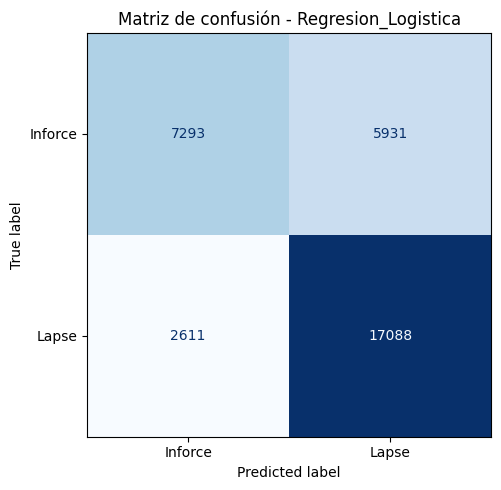


Matriz de confusión: Regresion_Logistica
              Predicho Inforce  Predicho Lapse
Real Inforce              7293            5931
Real Lapse                2611           17088


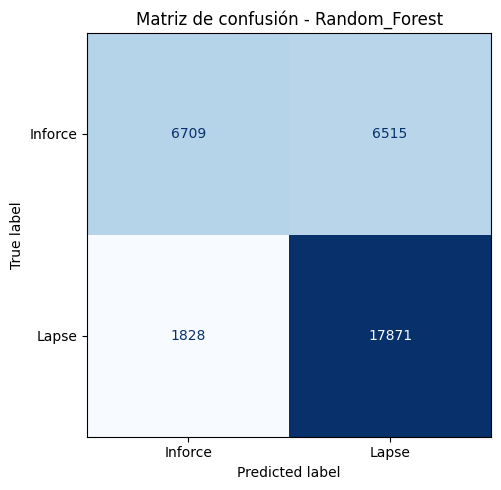


Matriz de confusión: Random_Forest
              Predicho Inforce  Predicho Lapse
Real Inforce              6709            6515
Real Lapse                1828           17871


In [74]:
import matplotlib.pyplot as plt
import pandas as pd
import mlflow

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

base = BASE
carpeta_graficos = base / "graficos"
carpeta_graficos.mkdir(parents=True, exist_ok=True)

modelos = {
    "Regresion_Logistica": mejor_logistica,
    "Random_Forest": mejor_forest
}

for nombre, modelo in modelos.items():

    # Generar predicciones
    y_pred = modelo.predict(X_test)

    # Calcular matriz de confusión
    matriz = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Crear gráfica
    fig, ax = plt.subplots(figsize=(7, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Inforce", "Lapse"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"Matriz de confusión - {nombre}"
    )

    plt.tight_layout()

    # Guardar gráfica
    ruta_grafica = (
        carpeta_graficos /
        f"matriz_confusion_{nombre}.png"
    )

    fig.savefig(
        ruta_grafica,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Registrar evidencia en MLflow
    with mlflow.start_run(
        run_name=f"{nombre}_Matriz_Confusion"
    ):
        mlflow.log_artifact(
            str(ruta_grafica),
            artifact_path="graficos"
        )

    print(f"\nMatriz de confusión: {nombre}")

    print(
        pd.DataFrame(
            matriz,
            index=["Real Inforce", "Real Lapse"],
            columns=["Predicho Inforce", "Predicho Lapse"]
        )
    )

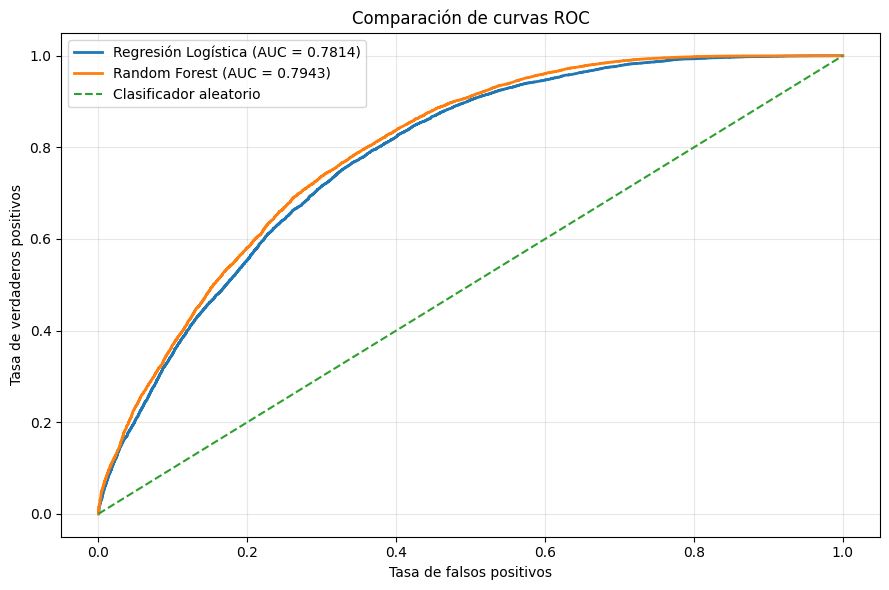

In [75]:
import matplotlib.pyplot as plt
import mlflow

from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

# Probabilidades de cancelación
prob_logistica = mejor_logistica.predict_proba(X_test)[:, 1]
prob_forest = mejor_forest.predict_proba(X_test)[:, 1]

# Calcular curvas ROC
fpr_log, tpr_log, _ = roc_curve(y_test, prob_logistica)
fpr_rf, tpr_rf, _ = roc_curve(y_test, prob_forest)

# Calcular áreas bajo la curva
auc_log = roc_auc_score(y_test, prob_logistica)
auc_rf = roc_auc_score(y_test, prob_forest)

# Crear gráfica
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    fpr_log,
    tpr_log,
    label=f"Regresión Logística (AUC = {auc_log:.4f})",
    linewidth=2
)

ax.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})",
    linewidth=2
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Comparación de curvas ROC")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Guardar gráfica
ruta_roc = BASE / "graficos" / "comparacion_roc.png"

ruta_roc.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(ruta_roc, dpi=150, bbox_inches="tight")

plt.show()
plt.close(fig)

# Registrar en MLflow
with mlflow.start_run(
    run_name="Comparacion_Curvas_ROC"
):
    mlflow.log_metric("roc_auc_logistica", auc_log)
    mlflow.log_metric("roc_auc_forest", auc_rf)

    mlflow.log_artifact(
        str(ruta_roc),
        artifact_path="graficos"
    )

print("\nCurvas ROC generadas correctamente.")
print("ROC-AUC Regresión Logística:", round(auc_log, 4))
print("ROC-AUC Random Forest:", round(auc_rf, 4))
print("Gráfica guardada en:", ruta_roc)

In [76]:
import pandas as pd
import mlflow

from statsmodels.stats.contingency_tables import mcnemar

# Predicciones de los modelos optimizados
pred_logistica = mejor_logistica.predict(X_test)
pred_forest = mejor_forest.predict(X_test)

# Identificar predicciones correctas
correcto_logistica = pred_logistica == y_test.to_numpy()
correcto_forest = pred_forest == y_test.to_numpy()

# Construir tabla de contingencia
tabla_mcnemar = pd.crosstab(
    pd.Series(correcto_logistica, name="Logistica_correcta"),
    pd.Series(correcto_forest, name="Forest_correcto")
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

print("TABLA DE CONTINGENCIA")
display(tabla_mcnemar)

# Prueba de McNemar
resultado = mcnemar(
    tabla_mcnemar.to_numpy(),
    exact=False,
    correction=True
)

print("\nEstadístico de McNemar:")
print(round(resultado.statistic, 4))

print("\nValor p:")
print(resultado.pvalue)

print("\nInterpretación:")

if resultado.pvalue < 0.05:
    print("Se rechaza H0: existe una diferencia estadísticamente significativa.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencia.")

# Registrar resultados en MLflow
with mlflow.start_run(run_name="Comparacion_Estadistica_McNemar"):

    mlflow.log_param("prueba", "McNemar")
    mlflow.log_param("nivel_significancia", 0.05)

    mlflow.log_metric(
        "estadistico_mcnemar",
        float(resultado.statistic)
    )

    mlflow.log_metric(
        "p_value",
        float(resultado.pvalue)
    )

    ruta_tabla = BASE / "resultados" / "tabla_mcnemar.csv"

    tabla_mcnemar.to_csv(ruta_tabla)
    mlflow.log_artifact(ruta_tabla)

print("\nResultados estadísticos registrados en MLflow.")

TABLA DE CONTINGENCIA


Forest_correcto,False,True
Logistica_correcta,,
False,7448,1094
True,895,23486



Estadístico de McNemar:
19.7104

Valor p:
9.010929716394214e-06

Interpretación:
Se rechaza H0: existe una diferencia estadísticamente significativa.

Resultados estadísticos registrados en MLflow.


## 11. Registro de modelos y reproducibilidad

Se registran los pipelines en MLflow y se comprueba que los modelos recuperados generan predicciones idénticas.

In [79]:

import mlflow
import mlflow.sklearn

# Modelos optimizados
modelos_finales_mlflow = {
    "Regresion_Logistica": mejor_logistica,
    "Random_Forest": mejor_forest
}

# Tipos autorizados para nuestros modelos propios
tipos_confiables = [
    "numpy.dtype",
    "sklearn.compose._column_transformer._RemainderColsList",
    "sklearn.tree._tree.Tree"
]

# Guardar identificadores de las nuevas ejecuciones
runs = {}

for nombre, modelo in modelos_finales_mlflow.items():

    with mlflow.start_run(
        run_name=f"{nombre}_Modelo_Final"
    ) as run:

        parametros = modelo.named_steps[
            "clasificador"
        ].get_params()

        for clave in [
            "C",
            "max_iter",
            "n_estimators",
            "max_depth",
            "min_samples_leaf",
            "max_features",
            "class_weight",
            "random_state"
        ]:
            if clave in parametros:
                mlflow.log_param(
                    clave,
                    str(parametros[clave])
                )

        mlflow.sklearn.log_model(
            sk_model=modelo,
            name="modelo",
            serialization_format="skops",
            skops_trusted_types=tipos_confiables
        )

        runs[nombre] = run.info.run_id

        print(
            f"Modelo registrado: {nombre}"
        )
        print("Run ID:", runs[nombre])

print("\nAmbos modelos registrados correctamente.")


Random Forest registrado correctamente.
Run ID: 98cfd3cc381d483d8a0f9ea298927727


In [82]:
import mlflow
import mlflow.artifacts
import skops.io as sio
import numpy as np
from pathlib import Path

# Utilizar los Run ID generados en la celda anterior
assert set(runs) == {
    "Regresion_Logistica",
    "Random_Forest"
}, "Primero debe ejecutarse el registro de ambos modelos."

# Modelos originales
modelos_originales = {
    "Regresion_Logistica": mejor_logistica,
    "Random_Forest": mejor_forest
}

# Tipos autorizados para nuestros modelos propios
tipos_confiables = [
    "numpy.dtype",
    "sklearn.compose._column_transformer._RemainderColsList",
    "sklearn.tree._tree.Tree"
]

# Recuperar experimento
experimento = mlflow.get_experiment_by_name(
    "Clasificacion_Polizas_Seguros"
)

cliente = mlflow.MlflowClient()

modelos_registrados = cliente.search_logged_models(
    experiment_ids=[experimento.experiment_id]
)

muestra = X_test.head(100).copy()

for nombre, run_id in runs.items():

    print("\n" + "=" * 50)
    print("MODELO:", nombre)

    encontrados = [
        modelo for modelo in modelos_registrados
        if modelo.source_run_id == run_id
    ]

    if not encontrados:
        raise RuntimeError(
            f"No se encontró el modelo: {nombre}"
        )

    # Descargar artefactos del modelo
    ruta_local = mlflow.artifacts.download_artifacts(
        artifact_uri=encontrados[0].model_uri
    )

    # Localizar archivo de serialización
    archivos_skops = list(
        Path(ruta_local).rglob("*.skops")
    )

    if len(archivos_skops) != 1:
        raise RuntimeError(
            f"Se esperaban 1 archivo .skops y "
            f"se encontraron {len(archivos_skops)}"
        )

    # Cargar únicamente nuestro modelo de confianza
    modelo_recuperado = sio.load(
        archivos_skops[0],
        trusted=tipos_confiables
    )

    # Comparar predicciones
    pred_original = modelos_originales[nombre].predict(
        muestra
    )

    pred_recuperado = modelo_recuperado.predict(
        muestra
    )

    coincidencia = np.array_equal(
        pred_original,
        pred_recuperado
    )

    print("Modelo recuperado correctamente.")
    print("Predicciones idénticas:", coincidencia)

    assert coincidencia

print("\nVerificación de reproducibilidad completada.")


MODELO: Regresion_Logistica
Modelo recuperado correctamente.
Predicciones idénticas: True

MODELO: Random_Forest
Modelo recuperado correctamente.
Predicciones idénticas: True

Verificación de reproducibilidad completada.


In [83]:
import mlflow
import pandas as pd

# Recuperar experimento
experimento = mlflow.get_experiment_by_name(
    "Clasificacion_Polizas_Seguros"
)

# Consultar ejecuciones registradas
ejecuciones = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    output_format="pandas"
)

print("Total de ejecuciones registradas:")
print(len(ejecuciones))

# Seleccionar información relevante
columnas = [
    "run_id",
    "tags.mlflow.runName",
    "status",
    "start_time"
]

columnas_disponibles = [
    col for col in columnas
    if col in ejecuciones.columns
]

print("\nEjecuciones registradas en MLflow:")

display(
    ejecuciones[columnas_disponibles]
    .sort_values("start_time", ascending=False)
)

Total de ejecuciones registradas:
19

Ejecuciones registradas en MLflow:


,run_id,tags.mlflow.runName,status,start_time
0,98cfd3cc381d483d8a0f9ea298927727,Random_Forest_Modelo_Final,FINISHED,2026-10-18 23:05:52.809000+00:00
1,3b77240958ac4e04bda90274b48e85b1,Random_Forest_Modelo_Final,FAILED,2026-10-18 23:05:01.569000+00:00
2,935f462a5e5242168e6e5ee9bc4fa274,Regresion_Logistica_Modelo_Final,FINISHED,2026-10-18 23:04:48.049000+00:00
3,88d87ce0b0e94185b5ce5eca26a596e1,Regresion_Logistica_Modelo_Final,FAILED,2026-10-18 23:03:50.489000+00:00
4,1bf1b88af8e2426da05eeb8789f3d1f7,Comparacion_Estadistica_McNemar,FINISHED,2026-10-18 23:02:39.654000+00:00
5,232cc1dc4a354eee9ff097cb6292aaa6,Comparacion_Curvas_ROC,FINISHED,2026-10-18 23:01:50.474000+00:00
6,ead5ee1da2bd43468ec7f20676db4584,Random_Forest_Matriz_Confusion,FINISHED,2026-10-18 22:59:32.852000+00:00
7,70e8371de9b740caa668c71cfe859b34,Regresion_Logistica_Matriz_Confusion,FINISHED,2026-10-18 22:59:30.625000+00:00
8,d9973eb3d9954abe8de71f4dc34135ea,Comparacion_Final_Modelos,FINISHED,2026-10-18 22:58:37.272000+00:00
9,09bc2f95196943d3b423edb1d0a576c9,Random_Forest_Evaluacion_Final,FINISHED,2026-10-18 22:58:37.131000+00:00
